In [65]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


# reading the data
first of all before working with the data we will read it and then show what it contains and extract some information from it



In [66]:
train_data = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
train_data.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [67]:
# we see how much nan values in every column/feature
train_data.isnull().sum()
# we see how many rows we have in the whole data
len(train_data)


891

# handling missing values in age
now after we checked every column how many nan it has , we found out that age has around 177 missing values , so we need to gain some information about age column to see how we will deal with it

In [68]:
# this describe how the data behaves 
train_data['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

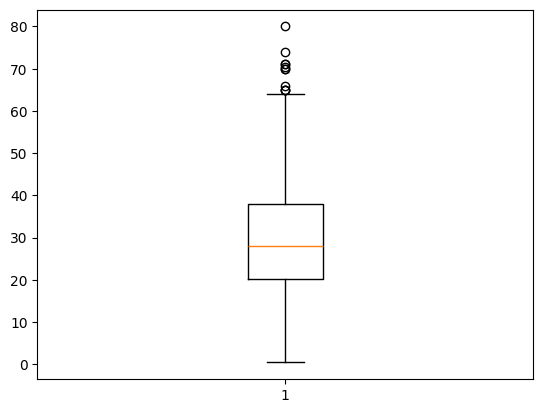

In [69]:
# detecting outliers
plt.boxplot(train_data['Age'].dropna())
plt.show()

# imputing missing values with median
median is robust to outliers , so we are going to use it to impute the missing values in age column

In [70]:
# splitting data into two groups related to who survived and who didn't
train_data.groupby('Survived')['Age'].describe()
age = train_data['Age'].to_numpy()
np.median(age)
np.mean(age)


np.float64(nan)

In [71]:
# filling the missing values with median
train_data['Age'] = train_data['Age'].fillna(train_data['Age'].median())
train_data.groupby('Survived')['Age'].describe()
train_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

# deleting columns 
cabin has about 77% of missing values , this is very big and it might affect our data so we will delete it 

In [72]:
# deleting cabin column
train_data.drop(columns=['Cabin'],inplace=True)
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [73]:
# we count how many passengers boarded at each port.
train_data['Embarked'].value_counts()
# we will fill nan with most frequent occuring values since it's not numerical
train_data['Embarked'] = train_data['Embarked'].fillna(train_data['Embarked'].mode()[0])
# we will now change every string to a number so we can process the data later
train_data['Embarked'] = np.where(train_data['Embarked'] == 'S', 0,
                           np.where(train_data['Embarked'] == 'C', 2,
                           np.where(train_data['Embarked'] == 'Q', 1,2)))
train_data['Embarked'].value_counts()

Embarked
0    646
2    168
1     77
Name: count, dtype: int64

In [74]:
train_data.groupby('Survived')['Sex'].describe()

,count,unique,top,freq
Survived,,,,
0,549,2,male,468
1,342,2,female,233


# gender helps to determine who is more likely to survive
so it appears that both died , but the female were more likely to survive than male  , and so the probability of a persong being a female was more likely to survive than being a male

about 74% of female survived and 18.8% of male survived
about 26% of female died and 81.2% of male died

In [75]:
# ticket and name won't contribute much to the data so we delete it 
train_data.drop(columns=['Ticket' , 'Name'],inplace=True)

In [76]:
# we make it numerical so we can process it 
train_data['Sex'] = np.where(train_data['Sex'] == 'male' , 0 , 
                            np.where(train_data['Sex'] == 'female' , 1 , 1))
train_data['Sex'].value_counts()

Sex
0    577
1    314
Name: count, dtype: int64

In [77]:
train_data.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,0,22.0,1,0,7.2500,0
1,2,1,1,1,38.0,1,0,71.2833,2
2,3,1,3,1,26.0,0,0,7.9250,0
3,4,1,1,1,35.0,1,0,53.1000,0
4,5,0,3,0,35.0,0,0,8.0500,0


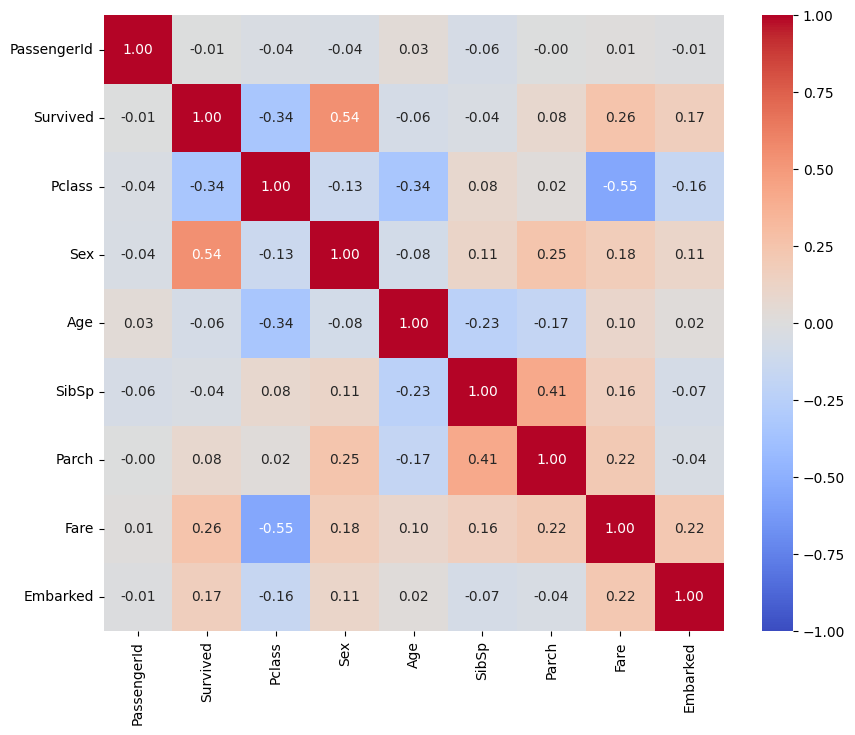

In [78]:
train_data.head()
numeric_cols = train_data.select_dtypes(include=['number'])
corr = numeric_cols.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

# heatmap 
from this heatmap we can conclude a lot of things:


1- sex is positively correlated to survival

2- pclass is negatively correlated , so the ammount of people who survive is people with lower pclass

3- the amount of fare paid also correlates in the ammount of  people who is going to survive 

4- age doesn't contribute as much in the ammount of people who survived 